Task 2.0 - Linear Regreesion  
* Finding Closing price (Close) from a dataset of 16 features and 283,085 training examples  
* Deadline - 20th Oct  
-Aparajaya

In [620]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

In [621]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print(f"Original train shape : {train.shape}")
print(f"Original test shape : {test.shape}")

Original train shape : (283085, 19)
Original test shape : (177063, 19)


In [622]:
features = ['high','low','momentum_index','beta_indicator','risk_premium','index','volatility_factor','technical_score','oscillator_value','liquidity_ratio','open','quant_index','trend_strength','market_sentiment','volume','alpha_signal']
target = 'close'

all_cols = features+[target]
train.dropna(subset=all_cols, inplace=True)
test.dropna(subset=all_cols, inplace=True)

X_train = train[features].values
Y_train = train['close'].values
X_test = test[features].values
Y_test = test['close'].values

print(f"Cleaned X_train shape = {X_train.shape}")
print(f"Cleaned X_test shape = {X_test.shape}")

Cleaned X_train shape = (264352, 16)
Cleaned X_test shape = (173655, 16)


In [623]:
#Normalization
mean_X = X_train.mean(axis=0)
mean_Y = Y_train.mean(axis=0)
sd_X = X_train.std(axis=0)
sd_Y = Y_train.std(axis=0)

X_train = (X_train - mean_X)/sd_X
Y_train = (Y_train - mean_Y)/sd_Y

In [624]:
def predict(X,w,b):
    return np.dot(X,w)+b

In [625]:
def cost(X,Y,Y_pred):
    m, = Y.shape
    J = (1/(2*m))*np.sum((Y_pred-Y)**2)
    return J

In [626]:
def results(X,Y_pred,Y_actual):
    SS_res = np.sum((Y_actual - Y_pred)**2)
    SS_tot = np.sum((Y_actual - np.mean(Y_actual)) ** 2)
    m,n = X.shape

    r_squared = 1 - SS_res/SS_tot
    adj_r_squared = 1 - (1-r_squared) * (m-1) / (m-n-1)
    mse = ((Y_actual - Y_pred)**2).mean()
    rmse = math.sqrt(mse)

    return r_squared,adj_r_squared,mse,rmse

In [627]:
def gradient_descent(X,Y,w,b,alpha,epochs):
    m, = Y.shape
    J_history = []

    for i in range (epochs):
        Y_pred = predict(X,w,b)
        w_temp = w - (alpha/m)*np.dot(X.T,(Y_pred-Y))
        b_temp = b - (alpha/m)*np.sum(Y_pred-Y)
        w,b = w_temp,b_temp
        J = cost(X,Y,Y_pred)
        J_history.append(J) 

        if i%10 == 0 or i == epochs-1:
           
            r_squared,adj_r_squared,mse,rmse = results(X_train,Y_pred,Y_train)
            print(f"Epoch {i} : Cost={J:.6f} | R^2={r_squared:.4f} | Adjusted R^2={adj_r_squared:.4f} | Mean squared error={mse:.4f} | Root Mean squared error={rmse:.4f}")
    
    return w,b,J_history


In [628]:
#Calling all functions for training data
initial_w = np.zeros(X_train.shape[1])
initial_b = 0
iterations = 100
alpha = 0.37

w_final,b_final,J_history = gradient_descent(X_train,Y_train,initial_w,initial_b,alpha,iterations)

print()
print("Final results for training :")
Y_pred = predict(X_train,w_final,b_final)
r_squared,adj_r_squared,mse,rmse = results(X_train,Y_pred,Y_train)
print(f"Cost={J_history[iterations-1]:.6f} | R^2={r_squared:.4f} | Adjusted R^2={adj_r_squared:.4f} | Mean squared error={mse:.4f} | Root Mean squared error={rmse:.4f}")

Epoch 0 : Cost=0.500000 | R^2=0.0000 | Adjusted R^2=-0.0001 | Mean squared error=1.0000 | Root Mean squared error=1.0000
Epoch 10 : Cost=0.257679 | R^2=0.4846 | Adjusted R^2=0.4846 | Mean squared error=0.5154 | Root Mean squared error=0.7179
Epoch 20 : Cost=0.139247 | R^2=0.7215 | Adjusted R^2=0.7215 | Mean squared error=0.2785 | Root Mean squared error=0.5277
Epoch 30 : Cost=0.076163 | R^2=0.8477 | Adjusted R^2=0.8477 | Mean squared error=0.1523 | Root Mean squared error=0.3903
Epoch 40 : Cost=0.042483 | R^2=0.9150 | Adjusted R^2=0.9150 | Mean squared error=0.0850 | Root Mean squared error=0.2915
Epoch 50 : Cost=0.024472 | R^2=0.9511 | Adjusted R^2=0.9511 | Mean squared error=0.0489 | Root Mean squared error=0.2212
Epoch 60 : Cost=0.014827 | R^2=0.9703 | Adjusted R^2=0.9703 | Mean squared error=0.0297 | Root Mean squared error=0.1722
Epoch 70 : Cost=0.009654 | R^2=0.9807 | Adjusted R^2=0.9807 | Mean squared error=0.0193 | Root Mean squared error=0.1390
Epoch 80 : Cost=0.006877 | R^2=0

In [629]:
#Normalizing and calling all functions for testing data

X_test = (X_test - mean_X)/sd_X
Y_test = (Y_test - mean_Y)/sd_Y
Y_test_pred = predict(X_test,w_final,b_final)
r_squared,adj_r_squared,mse,rmse = results(X_test,Y_test_pred,Y_test)

print("Final results for testing :")
print(f"Cost={cost(X_test,Y_test,Y_test_pred):.6f} | R^2={r_squared:.4f} | Adjusted R^2={adj_r_squared:.4f} | Mean squared error={mse:.4f} | Root Mean squared error={rmse:.4f}")

Y_test_pred_actual = Y_test_pred * sd_Y + mean_Y
print()
print("Predicted Values :")
print(Y_test_pred_actual)

Final results for testing :
Cost=0.020663 | R^2=0.9587 | Adjusted R^2=0.9587 | Mean squared error=0.0413 | Root Mean squared error=0.2033

Predicted Values :
[ 34.61623243 120.95924534  53.28088667 ...  93.78651851   2.68000558
  20.63434089]


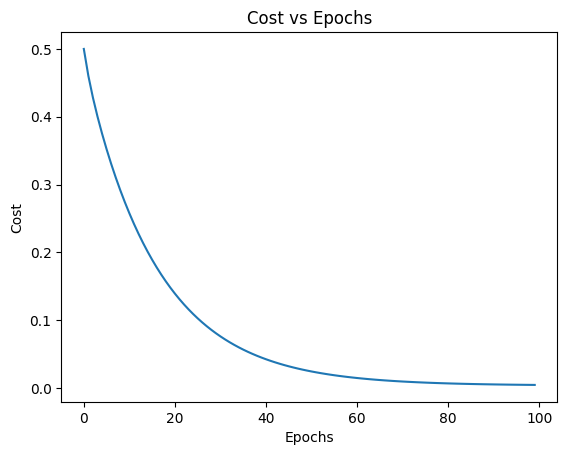

In [630]:
plt.plot(J_history)
plt.xlabel('Epochs')
plt.ylabel('Cost')
plt.title('Cost vs Epochs')
plt.show()

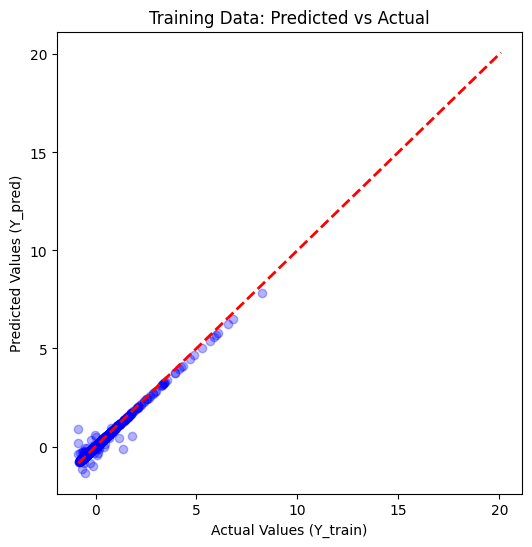

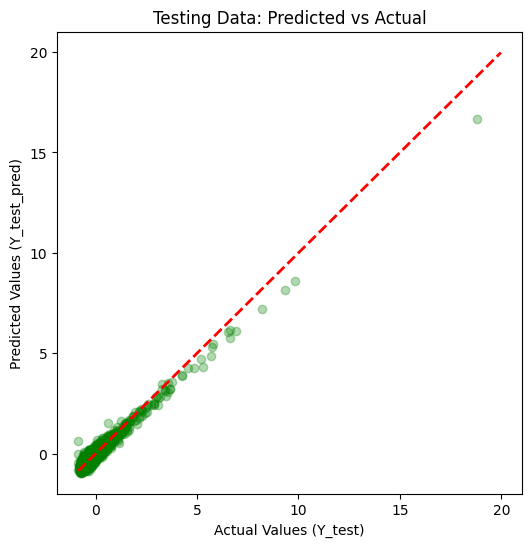

In [631]:
#Predicted vs Actual values for training data
sample_idx = np.random.choice(len(Y_train), size=2000, replace=False)

plt.figure(figsize=(6,6))
plt.scatter(Y_train[sample_idx], Y_pred[sample_idx], alpha=0.3, color='blue')
plt.plot([Y_train.min(), Y_train.max()], [Y_train.min(), Y_train.max()], 'r--', linewidth=2)
plt.xlabel("Actual Values (Y_train)")
plt.ylabel("Predicted Values (Y_pred)")
plt.title("Training Data: Predicted vs Actual")
plt.show()

#Predicted vs Actual values for testing data
sample_idx_test = np.random.choice(len(Y_test), size=2000, replace=False)

plt.figure(figsize=(6,6))
plt.scatter(Y_test[sample_idx_test], Y_test_pred[sample_idx_test], alpha=0.3, color='green')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual Values (Y_test)")
plt.ylabel("Predicted Values (Y_test_pred)")
plt.title("Testing Data: Predicted vs Actual")
plt.show()